<a href="https://colab.research.google.com/github/shreelakshmi470-ship-it/MySQL/blob/main/Assignment_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taxis

In [1]:
import seaborn as sns
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

In [2]:
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0]

if not missing_values.empty:
    print("Columns with missing values and their counts:")
    display(missing_values.sort_values(ascending=False))
else:
    print("No missing values found in the dataset.")

Columns with missing values and their counts:


,0
dropoff_zone,45
dropoff_borough,45
payment,44
pickup_zone,26
pickup_borough,26


Based on the missing values identified, I will now impute or remove them. For numerical columns, I will use the median for imputation to avoid skewing the distribution due to outliers. For categorical columns, I will use the mode. For critical columns where imputation is not suitable, I will remove the rows.

In [5]:
if 'tip' in df.columns:
    df['tip'] = df['tip'].fillna(df['tip'].median())
if 'tolls' in df.columns:
    df['tolls'] = df['tolls'].fillna(df['tolls'].median())

for col in ['pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].mode()[0])

missing_after_imputation = df.isnull().sum()
missing_after_imputation = missing_after_imputation[missing_after_imputation > 0]

if not missing_after_imputation.empty:
    print("Remaining missing values after imputation:")
    display(missing_after_imputation.sort_values(ascending=False))
else:
    print("All missing values have been handled.")

All missing values have been handled.


In [6]:
if 'payment' in df.columns:
    df.dropna(subset=['payment'], inplace=True)
    print("Rows with missing 'payment' values have been removed.")

final_missing_check = df.isnull().sum()
final_missing_check = final_missing_check[final_missing_check > 0]

if not final_missing_check.empty:
    print("Remaining missing values after all processing:")
    display(final_missing_check.sort_values(ascending=False))
else:
    print("All missing values have been successfully handled.")

Rows with missing 'payment' values have been removed.
All missing values have been successfully handled.


### Line Chart: Fare over Time

First, I'll convert the `pickup` column to datetime objects to enable time-series plotting. Then, I'll plot the fare against the pickup timestamp to visualize how fares change over time.

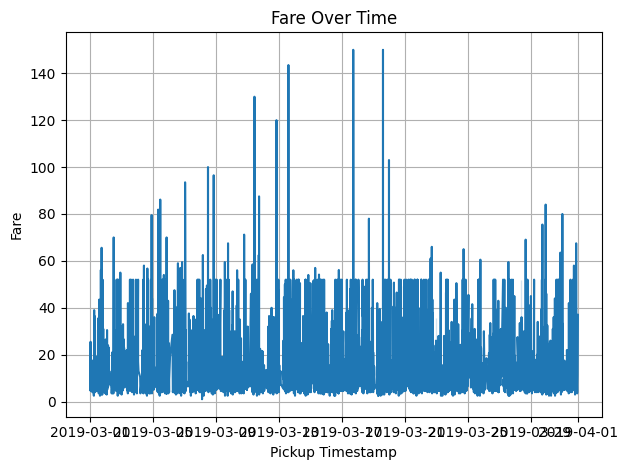

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df['pickup'] = pd.to_datetime(df['pickup'])

sns.lineplot(x='pickup', y='fare', data=df)
plt.title('Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare')
plt.grid(True)
plt.tight_layout()
plt.show()

### Bar Chart: Total Fare by Pickup Borough

Next, I'll aggregate the data by `pickup_borough` to calculate the total fare for each borough and visualize this with a bar chart.

/tmp/ipykernel_834/3919935704.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='pickup_borough', y='fare', data=total_fare_by_borough, palette='viridis')


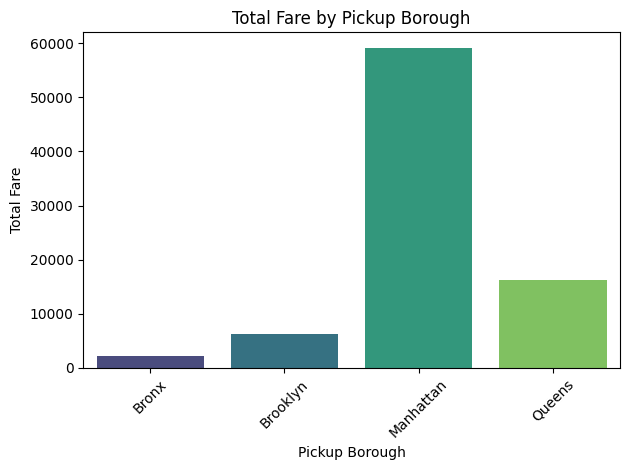

In [15]:
total_fare_by_borough = df.groupby('pickup_borough')['fare'].sum().reset_index()

sns.barplot(x='pickup_borough', y='fare', data=total_fare_by_borough, palette='viridis')
plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Pie Chart: Distribution of Payment Methods

Now, I'll create a pie chart to show the proportion of trips for each payment method.

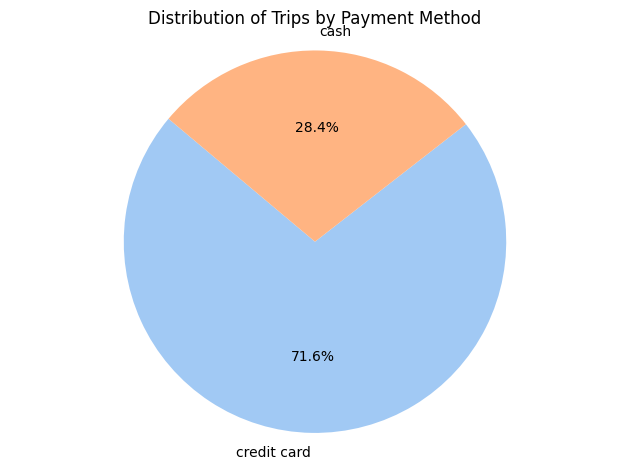

In [17]:
payment_counts = df['payment'].value_counts()

plt.pie(payment_counts, labels=payment_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Distribution of Trips by Payment Method')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.tight_layout()
plt.show()

### Histogram: Distribution of Distance

Here's a histogram to visualize the distribution of trip distances, allowing us to see the frequency of different distance ranges.

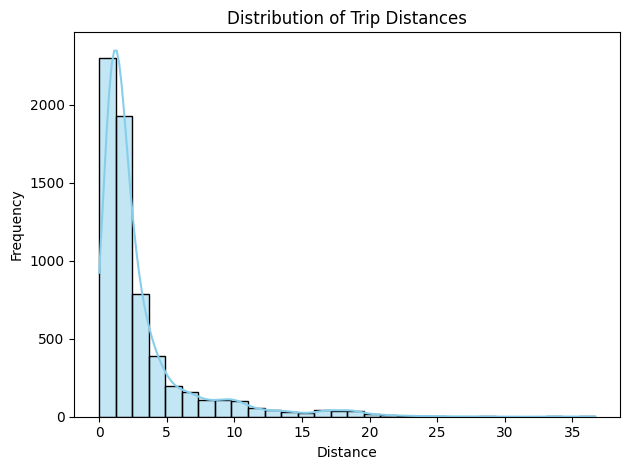

In [18]:
sns.histplot(df['distance'], bins=30, kde=True, color='skyblue')
plt.title('Distribution of Trip Distances')
plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

### Box Plot: Tip Amounts by Pickup Borough

Finally, I'll create a box plot to show the distribution of tip amounts across different `pickup_borough` values. This will help identify variations and outliers in tipping behavior by location.

/tmp/ipykernel_834/4195725179.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='pickup_borough', y='tip', data=df, palette='coolwarm')


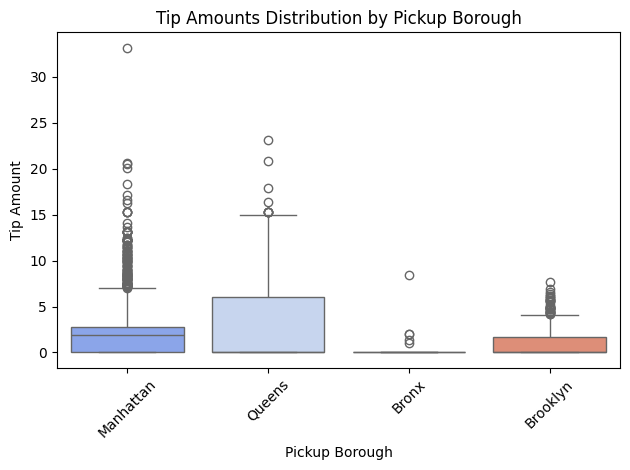

In [19]:
sns.boxplot(x='pickup_borough', y='tip', data=df, palette='coolwarm')
plt.title('Tip Amounts Distribution by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Count Plot: Trips by Pickup Borough

This count plot will show the total number of trips originating from each `pickup_borough`, giving an overview of the busiest areas.

/tmp/ipykernel_834/2063819802.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='pickup_borough', data=df, palette='magma')


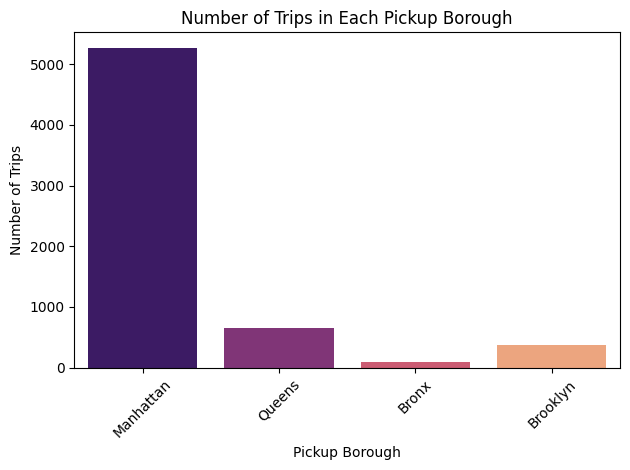

In [26]:
sns.countplot(x='pickup_borough', data=df, palette='magma')
plt.title('Number of Trips in Each Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Scatter Plot: Distance vs. Fare by Pickup Borough

This scatter plot will visualize the relationship between trip `distance` and `fare`, with points colored by `pickup_borough` to identify if the borough influences this relationship.

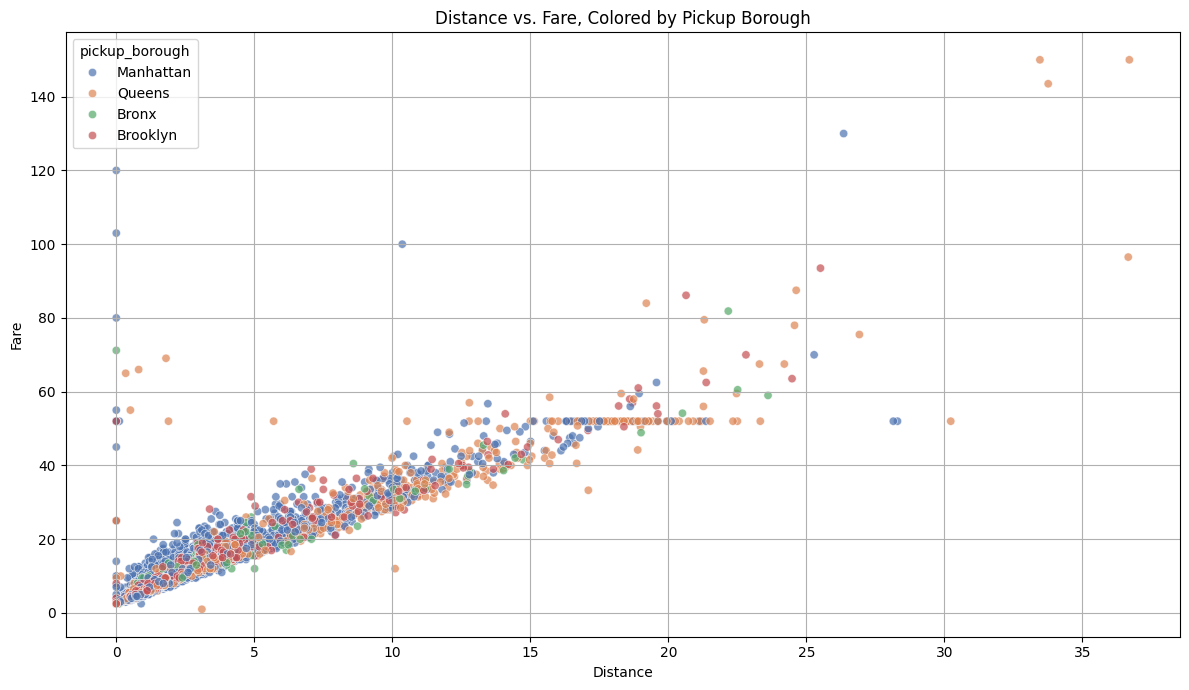

In [21]:
sns.scatterplot(x='distance', y='fare', hue='pickup_borough', data=df, palette='deep', alpha=0.7)
plt.title('Distance vs. Fare, Colored by Pickup Borough')
plt.xlabel('Distance')
plt.ylabel('Fare')
plt.grid(True)
plt.tight_layout()
plt.show()

### Heatmap: Correlation between Numerical Variables

To understand the relationships between numerical features, I'll generate a correlation matrix first and visualize it as a heatmap.

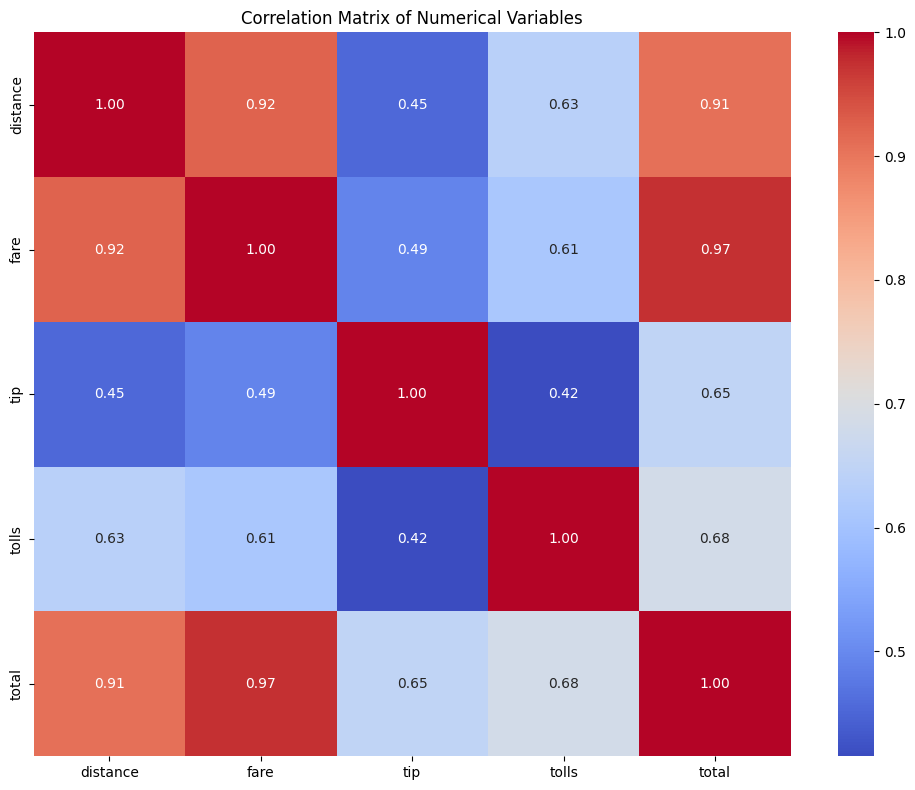

In [27]:
numerical_cols = ['distance', 'fare', 'tip', 'tolls', 'total']
correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

### Pair Plot: Pairwise Relationships by Pickup Zone

A pair plot will display pairwise relationships between `distance`, `fare`, `tip`, and `total`, with data points colored by `pickup_zone` to see how different zones interact with these variables.

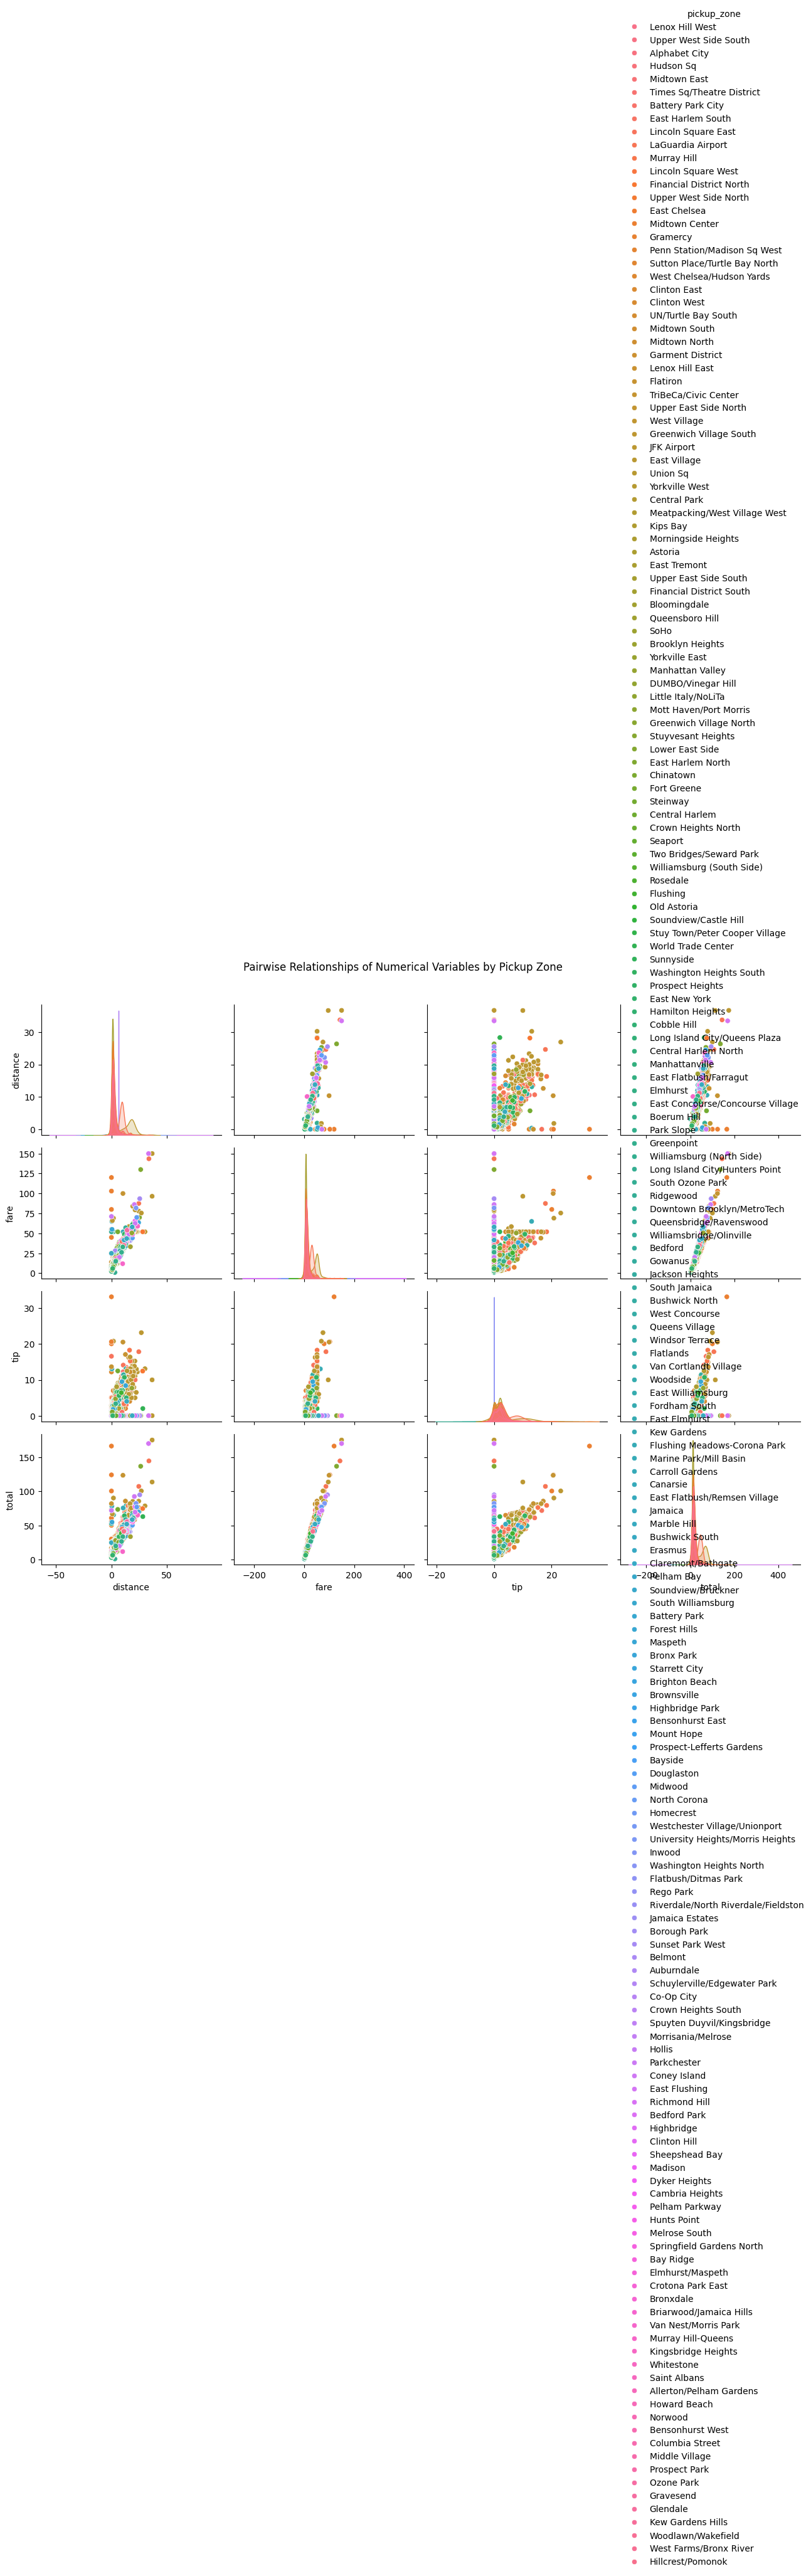

In [25]:
sns.pairplot(df, vars=['distance', 'fare', 'tip', 'total'], hue='pickup_zone', diag_kind='kde')
plt.suptitle('Pairwise Relationships of Numerical Variables by Pickup Zone', y=1.02) # Adjust suptitle position
plt.tight_layout()
plt.show()

### Violin Plot: Fare Distribution by Payment Method

Finally, a violin plot will illustrate the distribution of `fare` for each `payment` method, showing both the density and spread of fares for different payment types.

/tmp/ipykernel_834/957730183.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='payment', y='fare', data=df, palette='rocket')


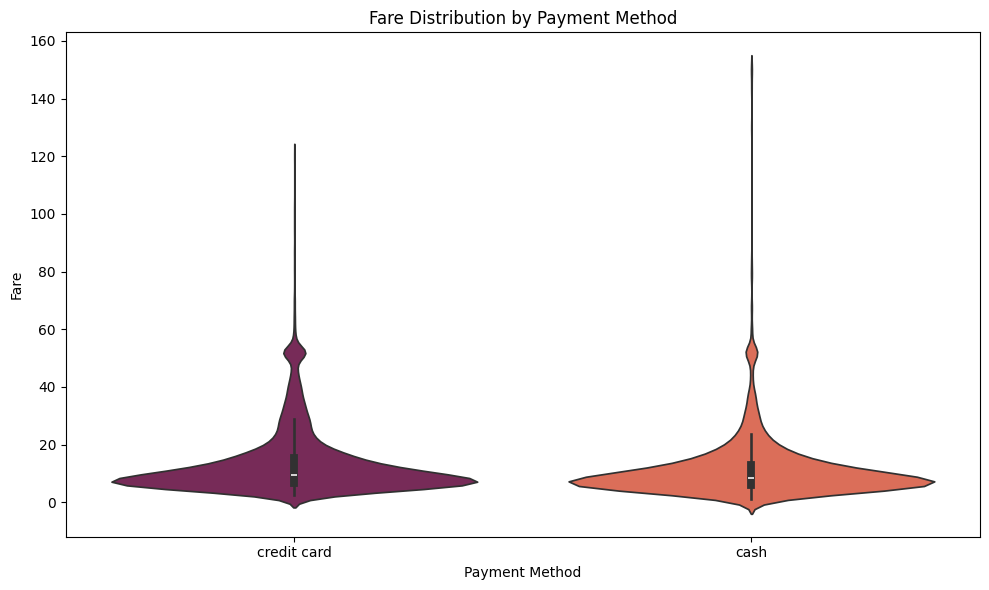

In [24]:
sns.violinplot(x='payment', y='fare', data=df, palette='rocket')
plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare')
plt.tight_layout()
plt.show()

# Thank you